# Mini assignment 4 Elisa Bucci

PCA via diagonalization of the covariance matrix

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.decomposition import PCA

1. The PCA function.

Given a centered data matrix $X$ ($n \times p$), its covariance matrix $C$ is symmetric, so it diagonalizes in an orthonormal basis:
$$C = P \Delta P^T,$$
where the columns of $P$ are the eigenvectors of $C$ and $\Delta$ is the diagonal matrix of eigenvalues, sorted in decreasing order. The PCA transformation of the data is $XP$. Or equivalently accoding to the notes if we define $P$ as the matric whose row are the eigenvcectors of the orthonormal basis, we have $C=P^T \Delta P$ and the PCA trasformation is $XP^T$.

In [2]:
def pca_eig(df, ddof=1):

    # Centering the data.
    X = np.array(df, dtype=float)
    X = X - np.mean(X, axis=0)

    # Covariance matrix and its diagonalization.
    C = np.cov(X, rowvar=False, ddof=ddof)
    eigenvalues, eigenvectors = np.linalg.eig(C)

    # C is symmetric, so eigenvalues and eigenvectors are real.
    eigenvalues = np.real(eigenvalues)
    eigenvectors = np.real(eigenvectors)

    # Sorting eigenvalues in decreasing order (and eigenvectors accordingly).
    order = np.argsort(eigenvalues)[::-1]
    Delta = np.diag(eigenvalues[order])
    P = eigenvectors[:, order]

    # PCA-transformation of the data.
    pc_arr = X @ P
    pc_df = pd.DataFrame(pc_arr, columns=['pc_' + str(k) for k in np.arange(0, pc_arr.shape[1])])

    return {'pc_df': pc_df, 'P': P, 'Delta': Delta}

2. The iris dataset.

In [3]:
def iris():

    # Loading the dataset.
    path_to_file = 'https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data'

    X = pd.read_csv(
        path_to_file,
        header=None,
        names=['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'variety']
    )

    # A bit of data engineering.
    X['variety'] = X['variety'].astype('category')
    relabelling_dct = {'Iris-setosa': 'setosa', 'Iris-versicolor': 'versicolor', 'Iris-virginica': 'virginica'}
    X['variety'] = X['variety'].cat.rename_categories(relabelling_dct)

    return X

In [4]:
iris_df = iris()
iris_df.head(8)

,sepal_length,sepal_width,petal_length,petal_width,variety
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
5,5.4,3.9,1.7,0.4,setosa
6,4.6,3.4,1.4,0.3,setosa
7,5.0,3.4,1.5,0.2,setosa


In [5]:
# Normalizing data (variety removed).
X = iris_df.drop(columns=['variety']).transform(lambda x: (x - x.mean())/x.std())

# PCA-transformation of the data.
pca_dct = pca_eig(X)
pc_df = pca_dct['pc_df']
P = pca_dct['P']
Delta = pca_dct['Delta']

In [6]:
print('P =')
print(np.round(P, 4))
print()
print('Delta =')
print(np.round(Delta, 4))

P =
[[ 0.5224 -0.3723 -0.721   0.262 ]
 [-0.2634 -0.9256  0.242  -0.1241]
 [ 0.5813 -0.0211  0.1409 -0.8012]
 [ 0.5656 -0.0654  0.6338  0.5235]]

Delta =
[[2.9108 0.     0.     0.    ]
 [0.     0.9212 0.     0.    ]
 [0.     0.     0.1474 0.    ]
 [0.     0.     0.     0.0206]]


In [7]:
pc_df.head(8)

,pc_0,pc_1,pc_2,pc_3
0,-2.256981,-0.504015,-0.121536,0.022996
1,-2.079459,0.653216,-0.226492,0.102864
2,-2.360044,0.317414,0.051308,0.027732
3,-2.296504,0.573447,0.098530,-0.066090
4,-2.380802,-0.672514,0.021356,-0.037272
5,-2.063623,-1.513478,0.030582,0.004384
6,-2.437545,-0.074314,0.341055,-0.037969
7,-2.226383,-0.246787,-0.082299,-0.025420


We check that $P$ is orthogonal, $P^T C P = \Delta$, and the total variance is preserved.

In [8]:
C = np.cov(X, rowvar=False, ddof=1)

print(np.allclose(P.T @ P, np.eye(P.shape[0])))
print(np.allclose(P.T @ C @ P, Delta))
print(np.trace(np.cov(X, rowvar=False, ddof=1)))
print(np.trace(np.cov(pc_df, rowvar=False, ddof=1)))

True
True
4.0
4.000000000000001


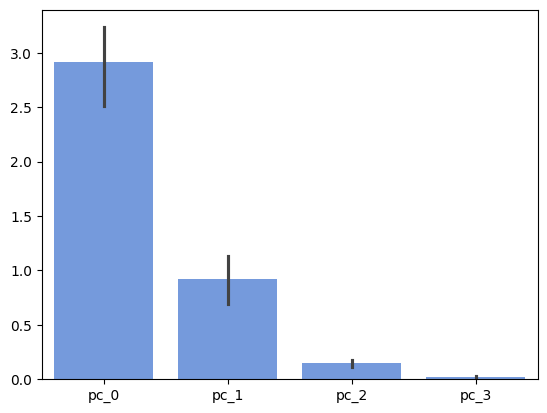

In [9]:
fig, ax = plt.subplots(1, 1)
plt.rcParams["figure.figsize"] = [6, 2.5]
sns.barplot(data=pc_df, estimator='var', color='cornflowerblue');

3. Comparison with the PCA learner of scikit-learn.

In [10]:
pca = PCA(n_components=None)
pca.fit(np.array(X))
pc_arr_sk = pca.transform(np.array(X))

print('sklearn components (rows) =')
print(np.round(pca.components_, 4))
print()
print('sklearn explained variances =', np.round(pca.explained_variance_, 4))
print('diagonal of Delta           =', np.round(np.diag(Delta), 4))

sklearn components (rows) =
[[ 0.5224 -0.2634  0.5813  0.5656]
 [ 0.3723  0.9256  0.0211  0.0654]
 [ 0.721  -0.242  -0.1409 -0.6338]
 [-0.262   0.1241  0.8012 -0.5235]]

sklearn explained variances = [2.9108 0.9212 0.1474 0.0206]
diagonal of Delta           = [2.9108 0.9212 0.1474 0.0206]


Eigenvectors are only defined up to sign, so the columns of $P$ may differ from the rows of `pca.components_` by a factor $-1$. We compare up to sign.

In [11]:
# Eigenvalues vs explained variances.
print(np.allclose(np.diag(Delta), pca.explained_variance_))

# P vs components (up to sign).
print(np.allclose(np.abs(P), np.abs(pca.components_.T)))

# Transformed data (up to sign, column by column).
signs = np.sign(np.sum(P * pca.components_.T, axis=0))
print(signs)
print(np.allclose(np.array(pc_df) * signs, pc_arr_sk))

True
True
[ 1. -1. -1. -1.]
True


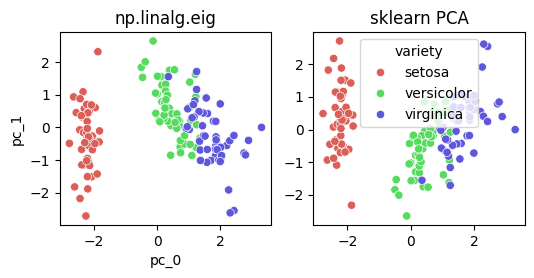

In [12]:
fig, ax = plt.subplots(1, 2)
plt.rcParams["figure.figsize"] = [10, 3]
plt.rcParams["figure.autolayout"] = True

sns.scatterplot(x=pc_df['pc_0'], y=pc_df['pc_1'], hue=iris_df['variety'], palette='hls', legend=False, ax=ax[0]);
sns.scatterplot(x=pc_arr_sk[:, 0], y=pc_arr_sk[:, 1], hue=iris_df['variety'], palette='hls', legend=True, ax=ax[1]);
ax[0].set_title('np.linalg.eig');
ax[1].set_title('sklearn PCA');

Conclusion. The two methods agree: the diagonal of $\Delta$ equals `pca.explained_variance_`, the columns of $P$ equal the rows of `pca.components_` up to sign, and the transformed datasets coincide up to the sign of each column. A sign flip only reflects a scatter plot across an axis, so it carries no information. Note that `sklearn` uses `ddof=1` for its variances, which is why `pca_eig` uses `ddof=1` by default.